# Ekman transport, enthalpy and Ekman advection maps

Maps of the pentad composites (`ekman_mse.jl`, written by `save_composite`), averaged over a period chosen here.

Two libraries, loaded with Revise `includet`, so edits to them take effect here without restarting the kernel:
- `composites.jl`: reading composites and computing the fields (`ekman_fields`), in sections: general (any composite file), pentad climatology, BSISO phases.
- `maps.jl`: plotting: settings, general maps (`panel` with `arrows` and `contours`, `plot_panels`), and overlays of `ekman_fields` (`stress_arrows`, `sst_contours`). The figures are written out in the notebooks, panel by panel.

Platform display settings (resolution, fonts, SVG) are in the first cell; the period and region in **Data**; color limits and axes in each figure's call.

Kernel: the Jupyter kernel "Julia" (IJulia; juliaup default Julia, project `plot/`). It shows each figure at the end of the cell that makes it, so there is no `display`; adjust a figure in that cell. The Julia extension's own "Julia release channel" kernel does not show figures automatically.

In [1]:
using Revise, Dates
includet("composites.jl") # reading composites, computing fields
includet("maps.jl")       # plotting

# display settings, which depend on the platform; change them here if figures look wrong or hang
plot_defaults!(; dpi=200) # inline figure size on screen (inches x dpi); fonts=[...]: font list
PythonPlot.svg(false)     # true: inline SVG, which scales to the pane (maps are rasterized, so it stays small)

false

## Data
`ekman_fields(file, first_day, last_day; n, lonlim, latlim, Ro_rad)`: the mean over the `n` pentads best aligned with the dates (year ignored; 365-day calendar; `n=nothing`: all pentads touching the dates), weighted by daily counts, in the region `lonlim`, `latlim` (only that region is read). It is `ekman_fields(read_period(file, first_day, last_day; n, lonlim, latlim); Ro_rad)`: read, then compute. Another period is one line (see the last section). `f_may` is a NamedTuple; `keys(f_may)` lists the fields, e.g. `f_may.adv_o`, `f_may.taux`; `f_may.dimval` the pentads. Gradients are NaN on the region's edge rows and columns.

The composites use the uncurtailed Ekman transport. `ekman_fields` multiplies M by `r = curtail(lat, Ro_rad)` (`f_may.r`), a function of latitude only, so `Ro_rad` can be changed here without recompositing. It matters only within ~5° of the equator.

In [2]:
file = "../ekman_pentad_clim_2012-2020.nc"
lonlim, latlim = (40, 110), (0, 25) # degrees: Indian Ocean; only this region is read
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
figtitle(f_may) = "$(basename(file)): $(period_label(f_may.dimval)) (Ro_rad = $(Ro_rad/1e3) km)"

# May: the 6 pentads best aligned with May (year ignored): pentads 25:30, May 1-30
f_may = ekman_fields(file, Date(2001, 5, 1), Date(2001, 5, 31); n=6, lonlim, latlim, Ro_rad)
f_may.dimval, size(f_may.Mx), keys(f_may)

f_jun = ekman_fields(file, Date(2001, 6, 1), Date(2001, 6, 30); n=6, lonlim, latlim, Ro_rad)
f_mayjun = ekman_fields(file, Date(2001, 5, 20), Date(2001, 6, 10); n=4, lonlim, latlim, Ro_rad)


(lon = [40.0, 40.25, 40.5, 40.75, 41.0, 41.25, 41.5, 41.75, 42.0, 42.25  …  107.75, 108.0, 108.25, 108.5, 108.75, 109.0, 109.25, 109.5, 109.75, 110.0], lat = [25.0, 24.75, 24.5, 24.25, 24.0, 23.75, 23.5, 23.25, 23.0, 22.75  …  2.25, 2.0, 1.75, 1.5, 1.25, 1.0, 0.75, 0.5, 0.25, 0.0], sst = [NaN NaN … NaN NaN; NaN NaN … NaN NaN; … ; NaN NaN … NaN NaN; NaN NaN … NaN NaN], t2 = [306.3395233154297 307.20123291015625 … 301.61326599121094 301.39405822753906; 306.94921875 307.56591033935547 … 301.6293029785156 301.49078369140625; … ; 297.77893829345703 298.49877166748047 … 299.8224639892578 299.9686508178711; 298.3917999267578 298.06898498535156 … 299.9283218383789 300.0755615234375], q = [0.004260223358869553 0.004481472773477435 … 0.014297320041805506 0.014474075520411134; 0.00428731320425868 0.004475838388316333 … 0.014545070473104715 0.01475139381363988; … ; 0.01675867335870862 0.01729789888486266 … 0.019584229681640863 0.01972167007625103; 0.0170872388407588 0.016994351521134377 … 0.019651

## Ekman transport, surface-air moist enthalpy $h_a$ and ocean-surface enthalpy $h_o$
Each figure is written out here: `plot_panels(f_may, [panel(x, title, units; cmap, vmin, vmax, arrows, contours), ...]; suptitle, ylim, xlim, ncols, figsize)`, one `panel` per map, in order, filling rows of `ncols` (default 2). Color limits are set at the top of each cell. Overlays: wind stress `arrows=stress_arrows(f_may; scale, key, keypos, every)`, `scale` N m$^{-2}$ per inch of arrow (smaller is longer), a `key` N m$^{-2}$ arrow at `keypos` (axes fraction), every `every`-th grid point; SST `contours=sst_contours(f_may; levels)` (°C). Units: `M_units`, `h_units` (kJ kg$^{-1}$), `flux_units` (W m$^{-2}$), `advT_units`, `tau_units`. `plot_panels` returns `(fig, axs, meshes, cbars, quivers, contoursets)`: axes `axs[row, col]` (from 0), and the color meshes, colorbars, arrows and contours of panel k, `meshes[k]`, `cbars[k]`, `quivers[k]`, `contoursets[k]`.

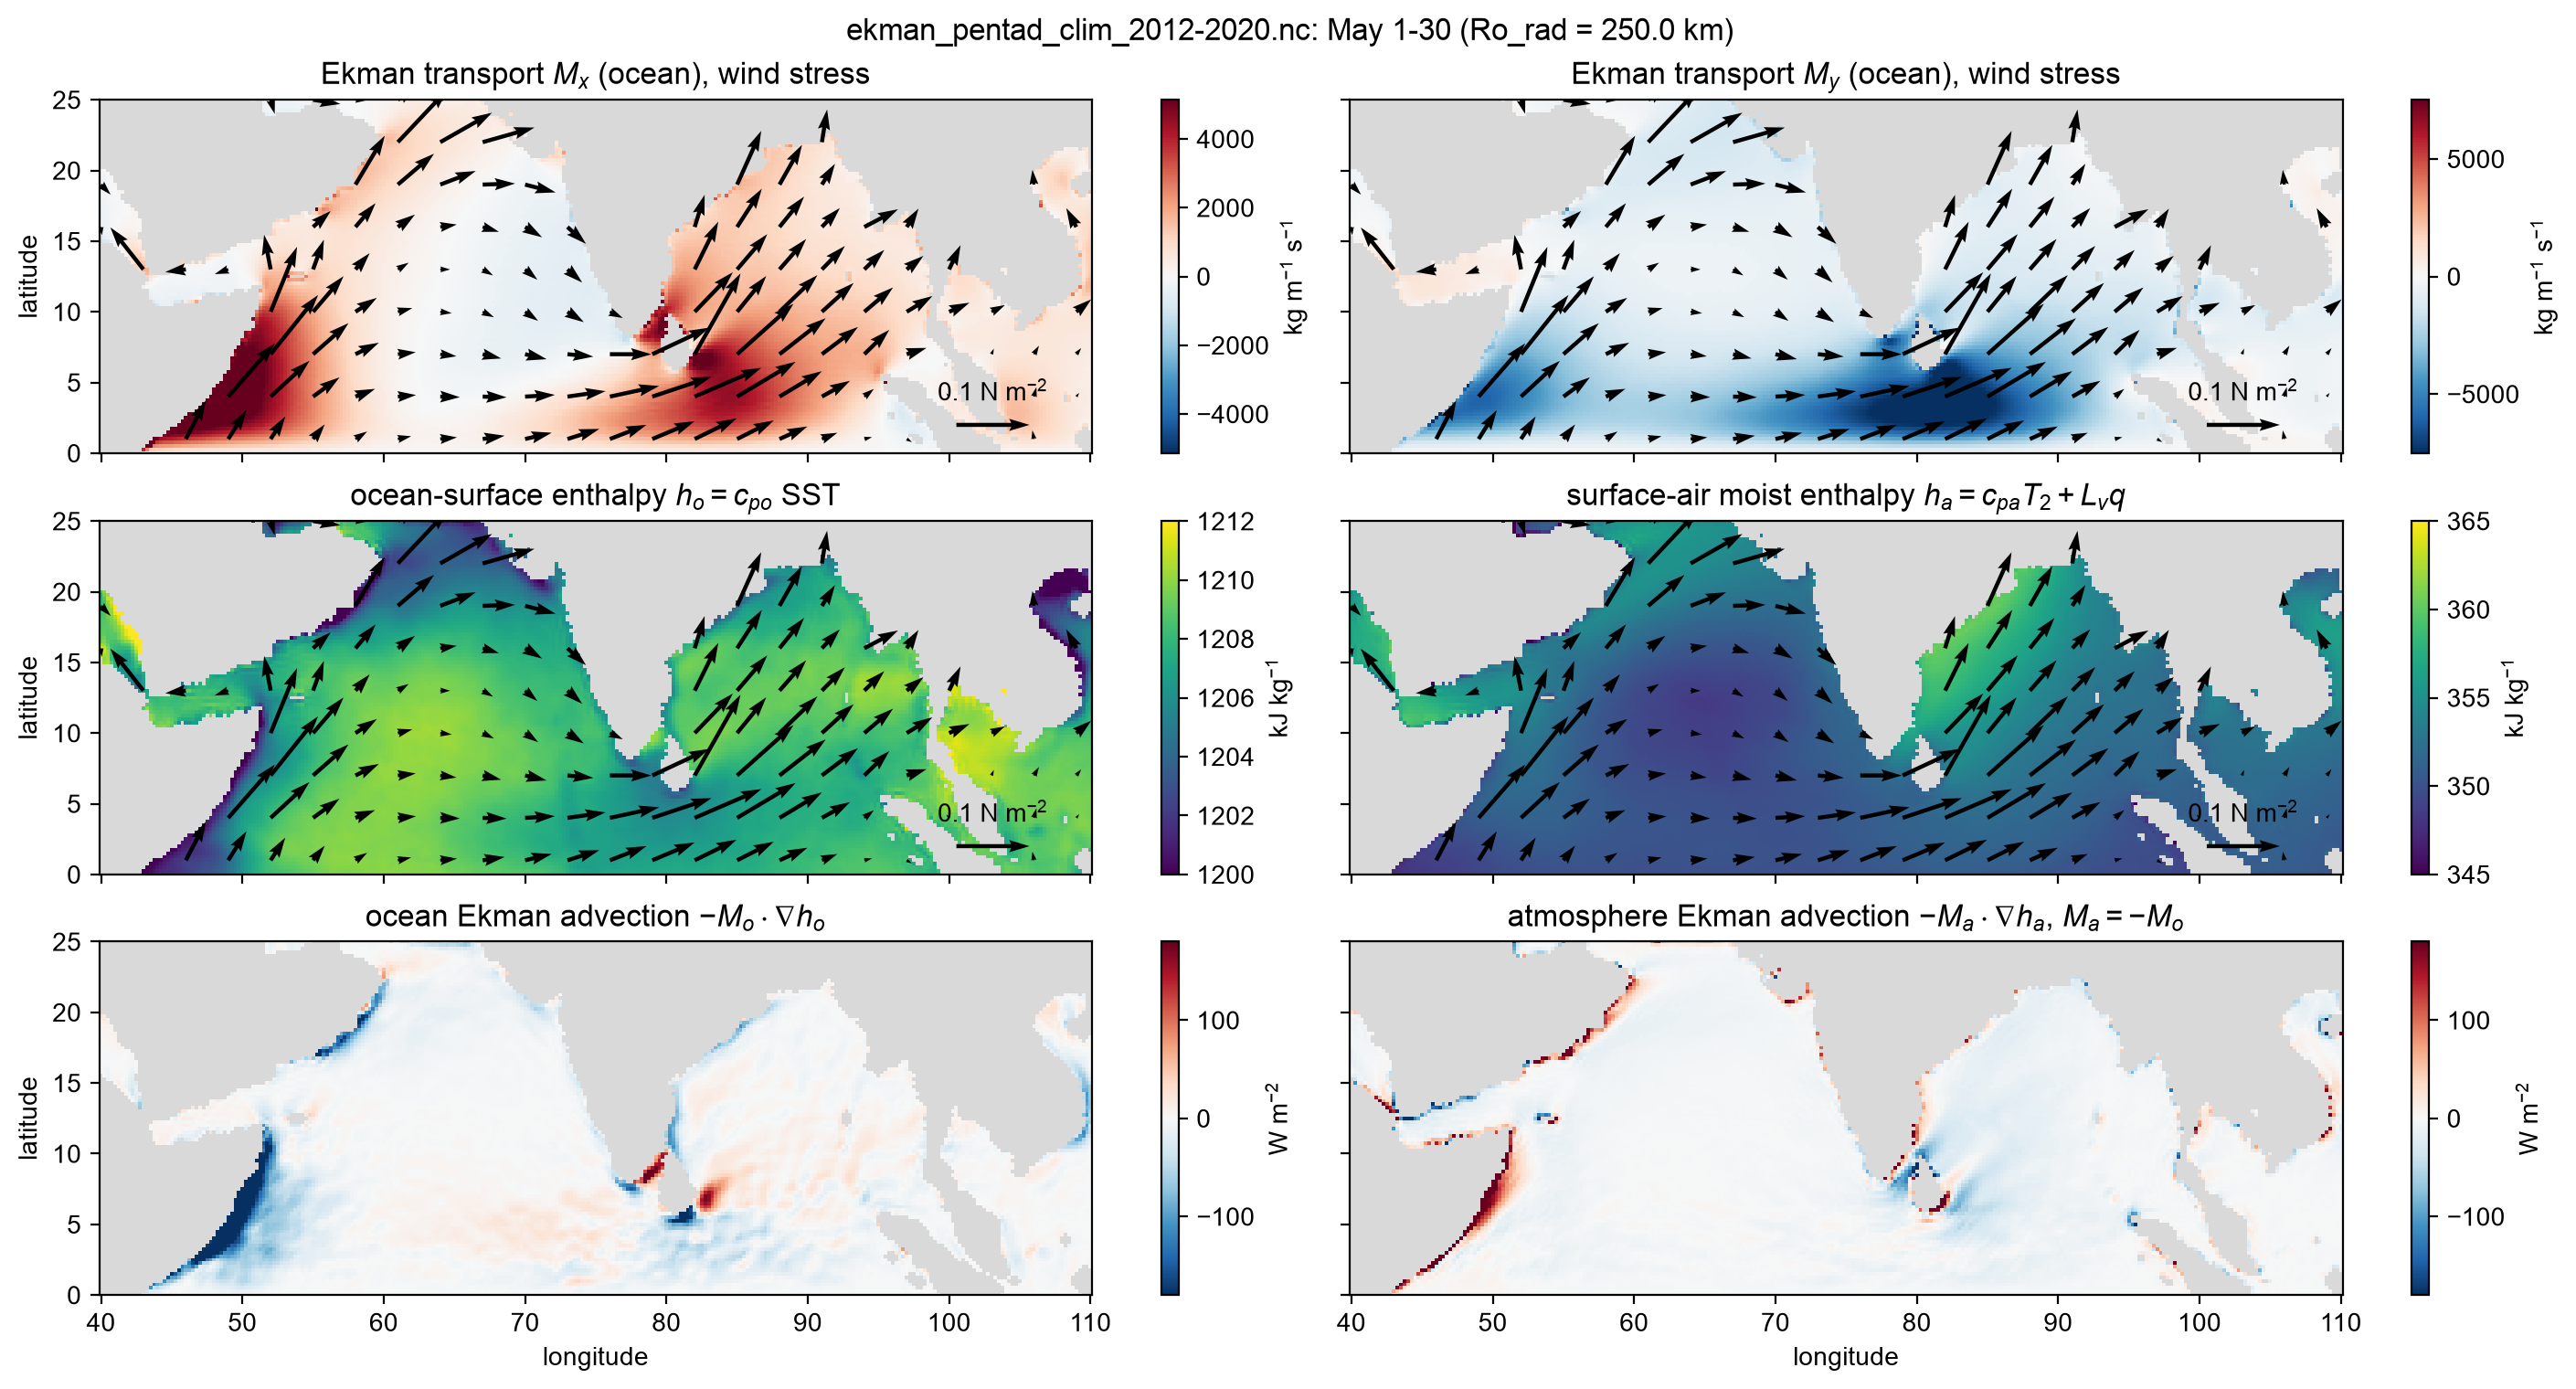

findfont: Failed to find font weight normal for Apple Chancery, now using 0.


In [3]:
ho_lims, ha_lims, advlim = (1200, 1212), (345, 365), 180 # color limits: kJ/kg, kJ/kg, ±W/m^2
tau = stress_arrows(f_may) # wind stress arrows: 0.25 N m^-2 per inch, 0.1 N m^-2 key
fig1, axs1, meshes1, cbars1, quivers1 = plot_panels(f_may, [
    panel(f_may.Mx, raw"Ekman transport $M_x$ (ocean), wind stress", M_units; arrows=tau),
    panel(f_may.My, raw"Ekman transport $M_y$ (ocean), wind stress", M_units; arrows=tau),
    panel(f_may.h_o ./ 1e3, raw"ocean-surface enthalpy $h_o = c_{po}$ SST", h_units; arrows=tau, cmap="viridis", vmin=ho_lims[1], vmax=ho_lims[2]),
    panel(f_may.h_a ./ 1e3, raw"surface-air moist enthalpy $h_a = c_{pa} T_2 + L_v q$", h_units; arrows=tau, cmap="viridis", vmin=ha_lims[1], vmax=ha_lims[2]),
    panel(f_may.adv_o, raw"ocean Ekman advection $-M_o \cdot \nabla h_o$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f_may.adv_a, raw"atmosphere Ekman advection $-M_a \cdot \nabla h_a$, $M_a = -M_o$", flux_units; vmin=-advlim, vmax=advlim)];
    suptitle=figtitle(f_may), ylim=latlim);
# adjust here, e.g. cbars1[3].set_ticks(1200:3:1212); axs1[0, 0].set_xlim(50, 100); quivers1[1].set_color("w")
# fig1.savefig("ekman_V_ha_ho_$(period_tag(f_may.dimval)).png"; bbox_inches="tight")

Atmosphere and ocean (moist) enthalpy color ranges are both 20 kJ/kg. The atmosphere has a gradient in the Bay of Bengal, but not much in the Arabian Sea. Theres a maximum (SST) in the central AS. Atmosphere and Ocean have nearly opposite (moist) enthalpy gradients around 20 N in the Arabian Sea. Both gradients result in cool advection, because of the southward ocean and northward atmosphere Ekman transport.

In [4]:
# Adjust a figure in the cell that makes it, after the figure call (axes axs1[row, col] from 0,
# colorbars cbars1[k], arrows quivers1[k] of panel k). The figure is drawn when that cell ends.

## Ocean and atmosphere Ekman advection and their sum
Columns: temperature (SST, $T_2$; mass-weighted, K kg m$^{-2}$ s$^{-1}$, ±`Tlim`), and enthalpy (ocean $h_o$) and moist enthalpy (atmosphere $h_a$), W m$^{-2}$, ±`Hlim`. Rows: ocean, atmosphere, sum, difference.

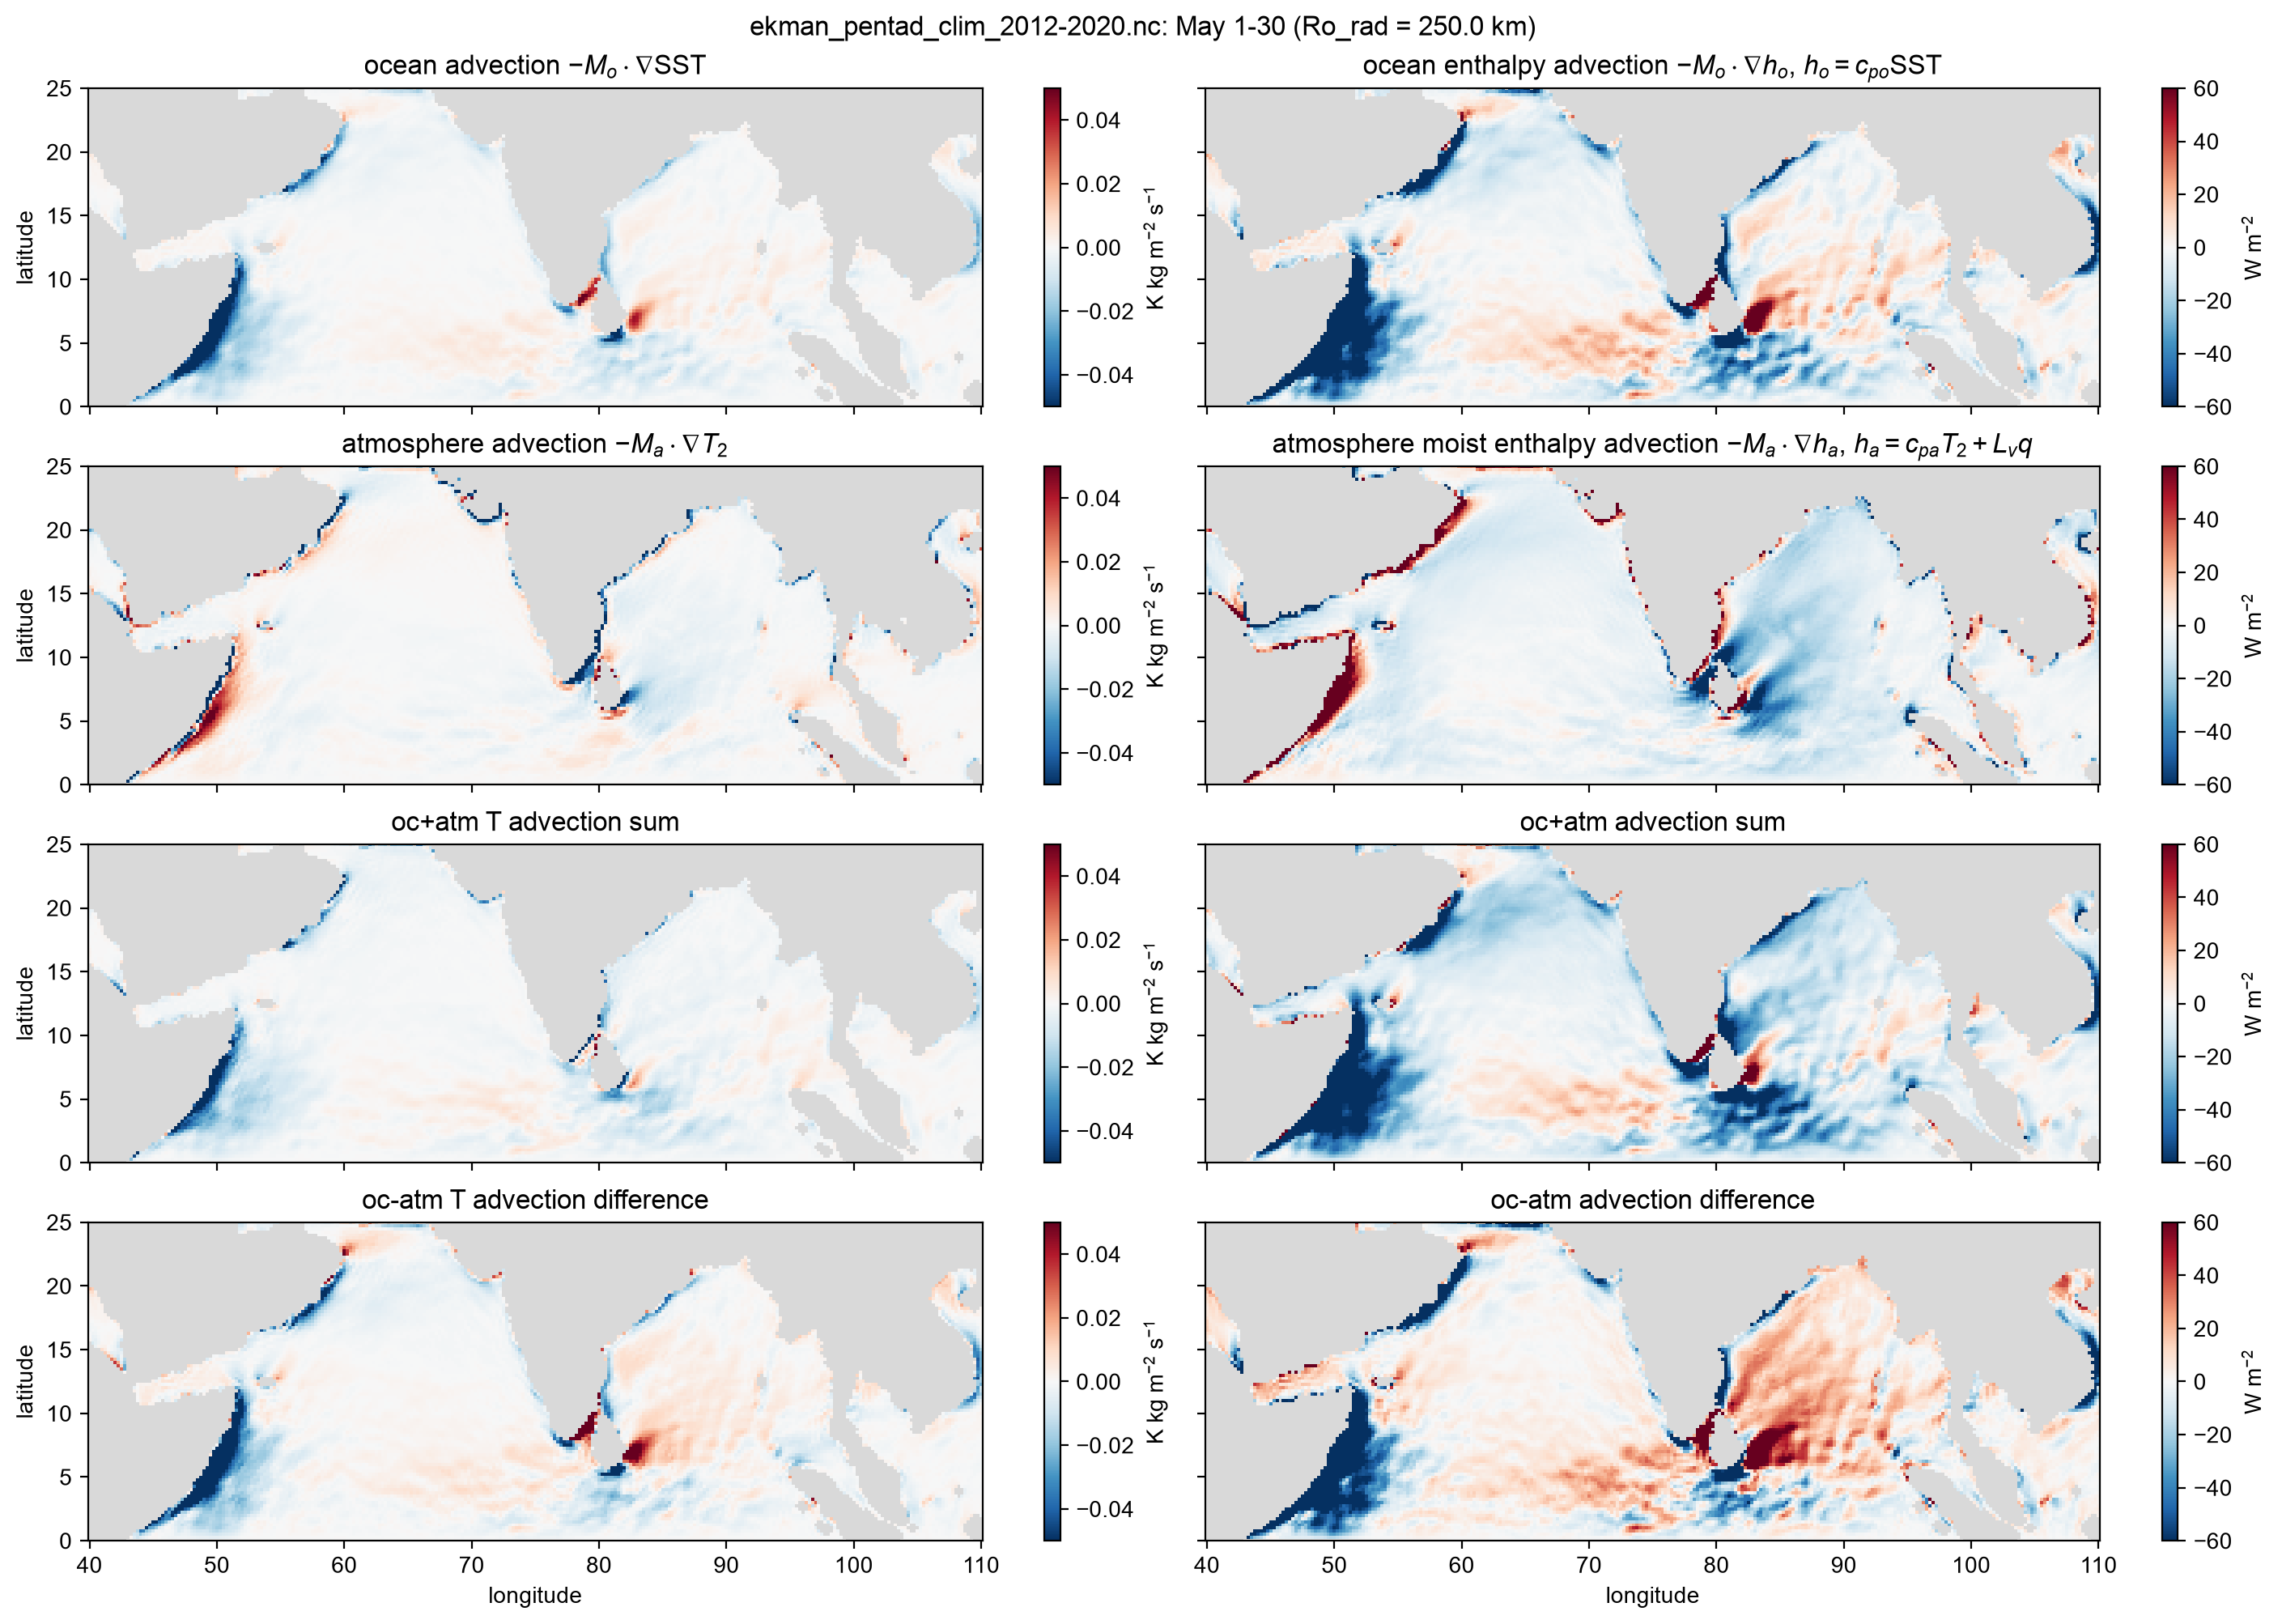

In [5]:
Tlim, Hlim = 0.05, 60 # color limits: ±K kg m^-2 s^-1 (temperature), ±W m^-2 (enthalpy)
fig_adv1, axs_adv1, meshes_adv1, cbars_adv1 = plot_panels(f_may, [
    panel(f_may.advT_o, raw"ocean advection $-M_o \cdot \nabla$SST", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f_may.adv_o, raw"ocean enthalpy advection $-M_o \cdot \nabla h_o$, $h_o = c_{po}$SST", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f_may.advT_a, raw"atmosphere advection $-M_a \cdot \nabla T_2$", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f_may.adv_a, raw"atmosphere moist enthalpy advection $-M_a \cdot \nabla h_a$, $h_a = c_{pa}T_2 + L_v q$", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f_may.advT_o .+ f_may.advT_a, "oc+atm T advection sum", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f_may.adv_o .+ f_may.adv_a, "oc+atm advection sum", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f_may.advT_o .- f_may.advT_a, "oc-atm T advection difference", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f_may.adv_o .- f_may.adv_a, "oc-atm advection difference", flux_units; vmin=-Hlim, vmax=Hlim)];
    suptitle=figtitle(f_may), ylim=latlim);
# fig_adv1.savefig("ekman_adv_sum_$(period_tag(f_may.dimval)).png"; bbox_inches="tight")

The ASTZ sum of Ekman advection is mostly cooling. It warms only where we might expect there to be an ISO atmospheric vortex (FNISO). The atmospheric cold advection of -10 W m$^2$ dominates everywhere in the open ocean. Ocean advection is more variable and takes both signs. It is notably positive in May along 5 N, 60-80 E.

The two signs in the difference plot (lowest right) demonstrate two regimes: 

(positive, red) Ekman advection warms ocean relative to atmosphere. 
This reflects atmospheric cooling advection by baroclinic frictional wind, which flows down pressure gradients from cool T to warmer T. 
This is expected for SST driving the surface wind response in the atmosphere.

(negative, blue) Ekman advection cools ocean relative to atmosphere. 
This reflects ocean cooling by advection from cool regions of SST, such as created by Ekman divergence and upwelling. 
This is expected for wind stress driving the surface temperature response in the ocean.

The monsoon influence the Ekman transport in the ocean. Both the wind and the SST gradient shift northward from May to June. In May, warming advection along 5N advects southward from the AS warm pool under westward winds. In June, the warming advection shifts northward, with a southeastward Ekman flux under the northeastward Findlater jet.

## Total ASTZ advection: saturated air enthalpy $h_*$ and the sea-air disequilibrium $h'_a$
Air saturated at the SST would have moist enthalpy $h_* = c_{pa}\mathrm{SST} + L_v q_{sat}(\mathrm{SST})$, with $q_{sat}$ the saturation specific humidity (Buck, 1000 hPa, as for $q$). The true surface air has $h_a = h_* - h'_a$, reduced by $h'_a = c_{pa}(\mathrm{SST} - T_2) + L_v(q_{sat}(\mathrm{SST}) - q)$, from the sea-air temperature difference and the saturation deficit. The ASTZ sum of Ekman advection splits as
$$-M_o \cdot \nabla(h_o - h_a) = -M_o \cdot \nabla(h_o - h_*) - M_o \cdot \nabla h'_a .$$
$h_o - h_*$ depends only on SST: $d(h_o - h_*)/d\mathrm{SST} = c_{po} - c_{pa} - L_v\, dq_{sat}/dT$, about $-1$ kJ kg$^{-1}$ K$^{-1}$ near 30 °C, so $-M_o \cdot \nabla h_o$ and $-M_o \cdot \nabla h_*$ nearly cancel (and $h_o - h_*$ decreases with SST). `f_may.adv_star` $= -M_o \cdot \nabla h_*$ is linearized: $c_{pa} + L_v q_{sat}'$ at the composite-mean SST times the composite of daily $-M_o \cdot \nabla\mathrm{SST}$. `f_may.adv_ha_prime` $= -M_o \cdot \nabla h'_a$ is the remainder, so the two terms sum exactly to the ASTZ sum.

The ocean Ekman transport advects the ASTZ enthalpy *difference* $h_o-h_a$ because of the reversed atmospheric Ekman flux. The Ekman transport is
$$
-M_o \cdot \nabla(h_o - h_a) = -M_o \cdot \nabla(h_o - h_* + h'_a) 
\approx -M_o \cdot \nabla h_o 
\approx -M_o \cdot \nabla h_* 
\approx -M_o \cdot \nabla h'_a.
$$

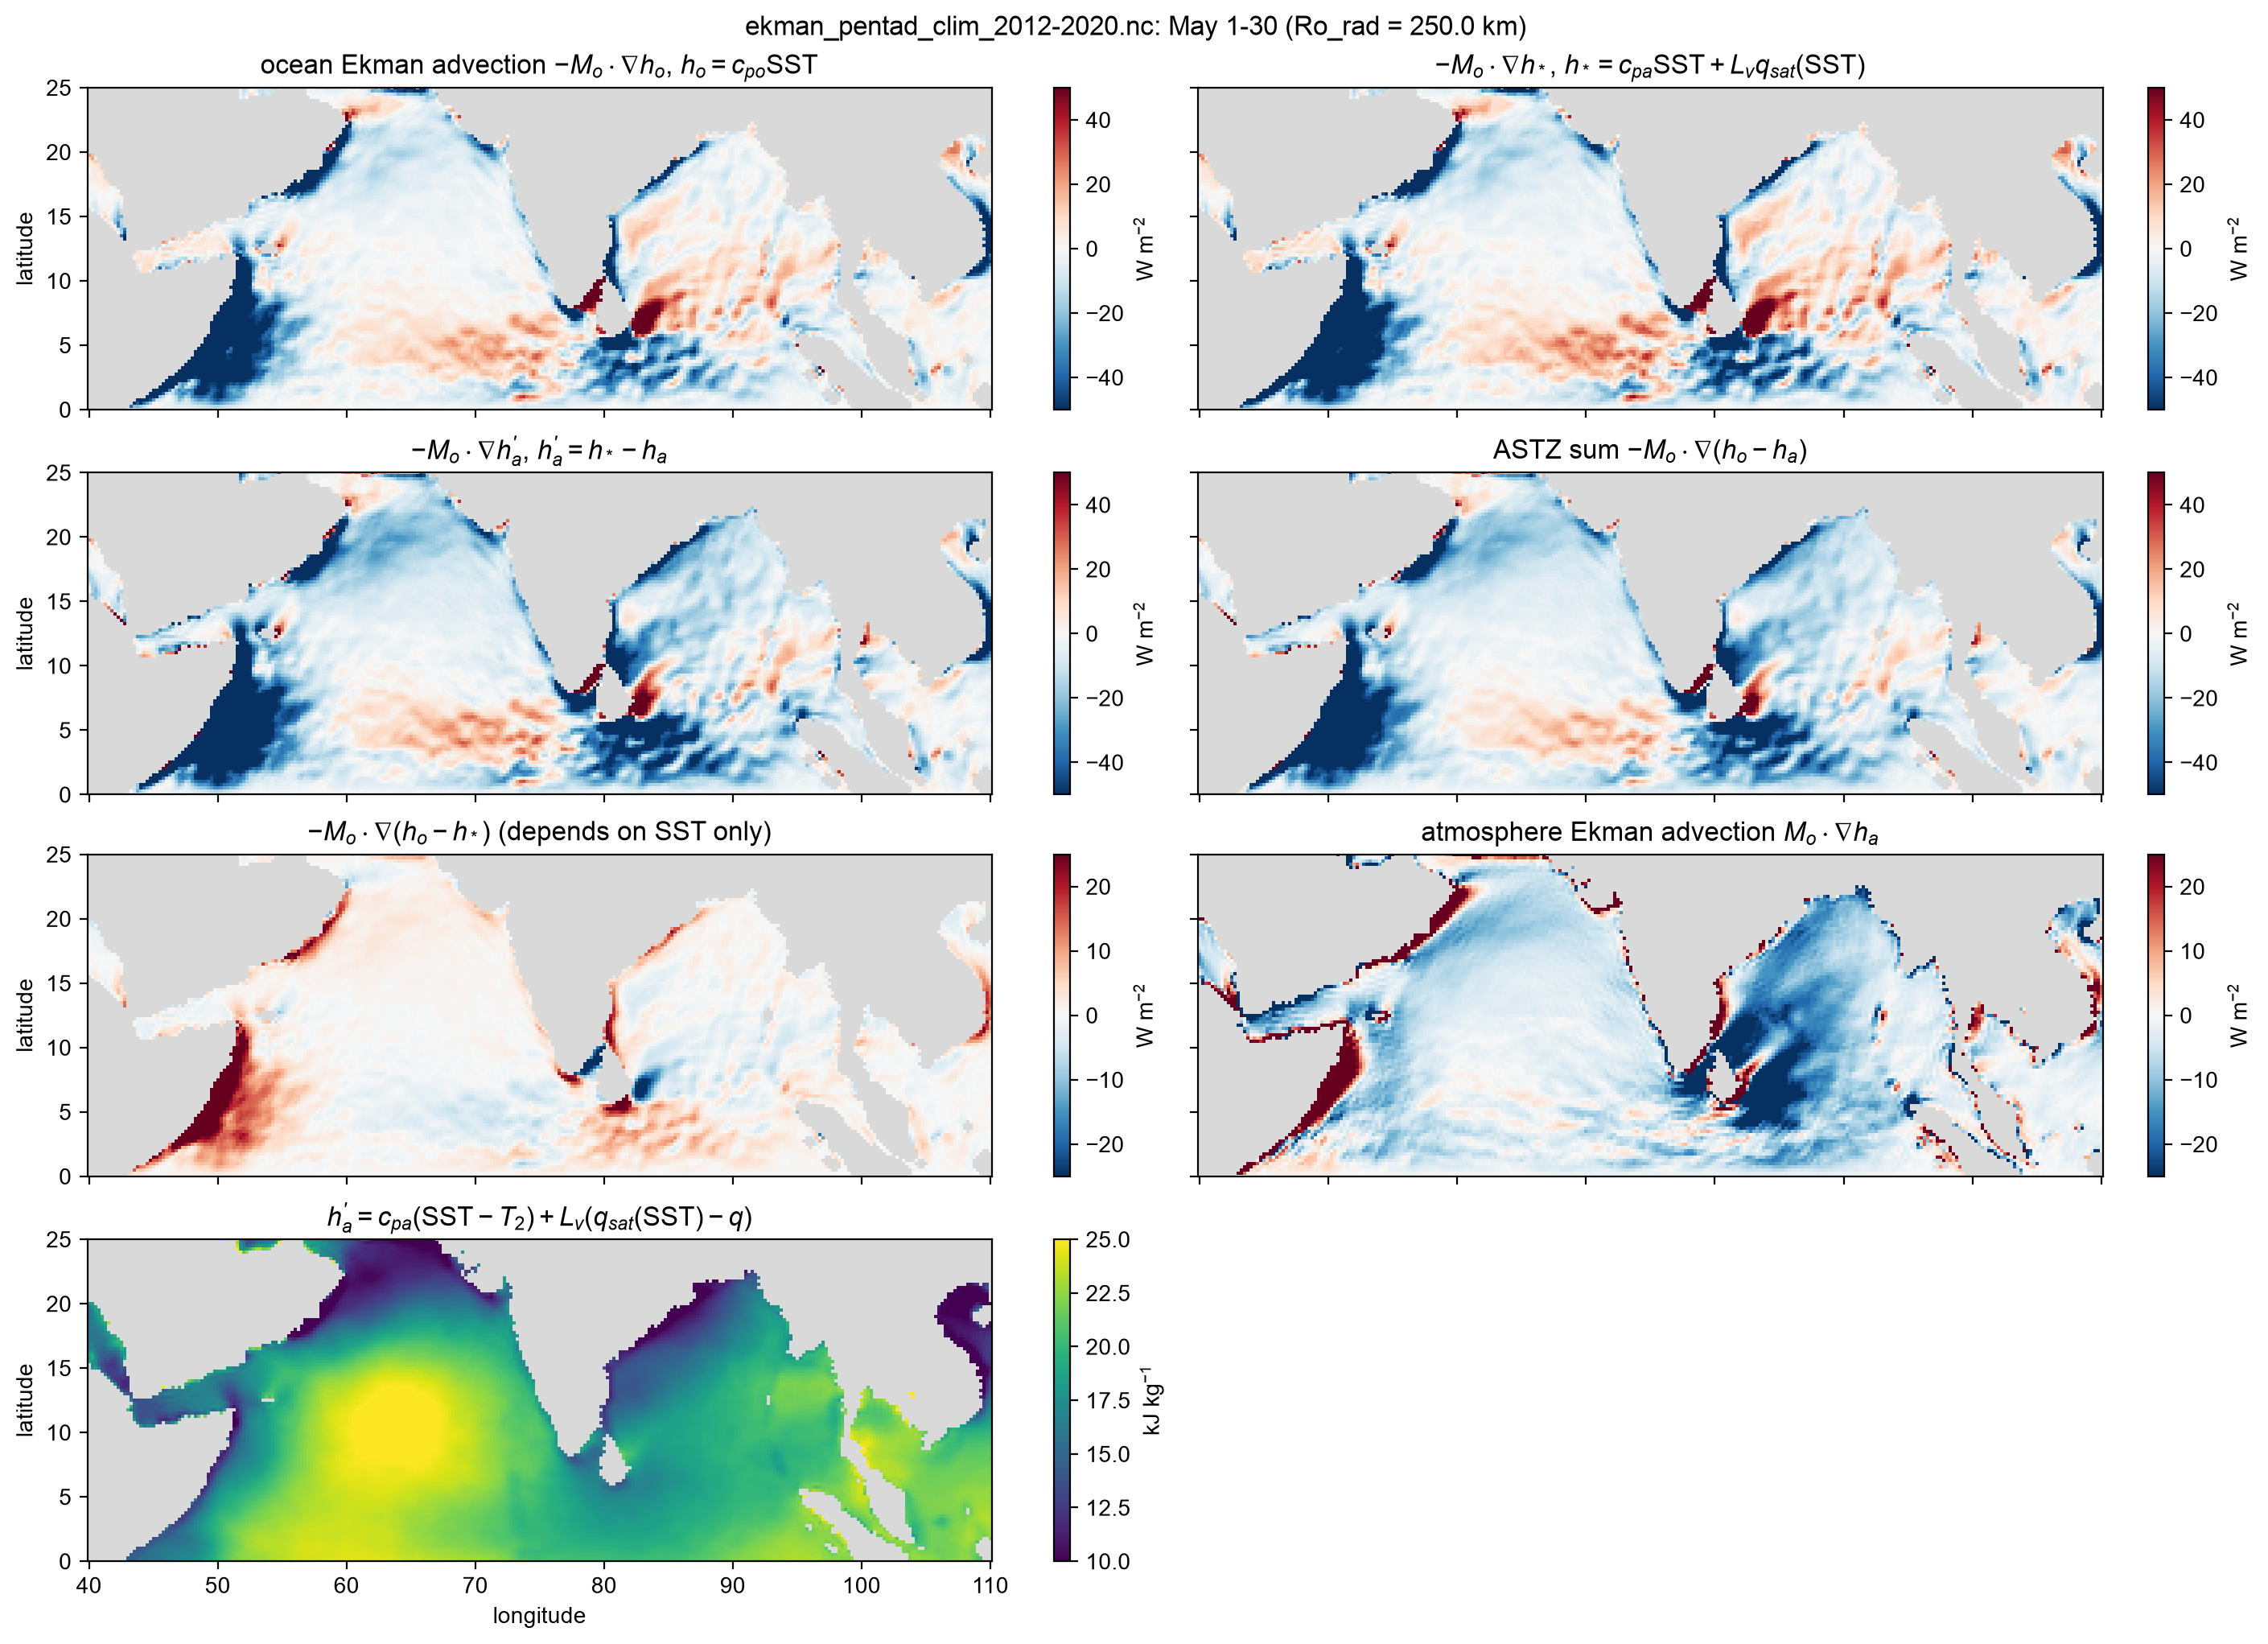

In [6]:
advlim, ha_prime_lims = 50, (10, 25) # color limits: ±W m^-2, kJ/kg
atmlim = 25
fig_astz1, axs_astz1, meshes_astz1, cbars_astz1 = plot_panels(f_may, [
    panel(f_may.adv_o, raw"ocean Ekman advection $-M_o \cdot \nabla h_o$, $h_o = c_{po}\mathrm{SST}$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f_may.adv_star, raw"$-M_o \cdot \nabla h_*$, $h_* = c_{pa}\mathrm{SST} + L_v q_{sat}(\mathrm{SST})$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f_may.adv_ha_prime, raw"$-M_o \cdot \nabla h_a'$, $h_a' = h_* - h_a$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f_may.adv_o .+ f_may.adv_a, raw"ASTZ sum $-M_o \cdot \nabla (h_o - h_a)$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f_may.adv_o .- f_may.adv_star, raw"$-M_o \cdot \nabla (h_o - h_*)$ (depends on SST only)", flux_units; vmin=-atmlim, vmax=atmlim),
    panel(f_may.adv_a, raw"atmosphere Ekman advection $M_o \cdot \nabla h_a$", flux_units; vmin=-atmlim, vmax=atmlim),
    panel(f_may.ha_prime ./ 1e3, raw"$h_a' = c_{pa}(\mathrm{SST} - T_2) + L_v (q_{sat}(\mathrm{SST}) - q)$", h_units;
          cmap="viridis", vmin=ha_prime_lims[1], vmax=ha_prime_lims[2])];
    suptitle=figtitle(f_may), ylim=latlim);
# fig_astz1.savefig("ekman_astz_hstar_ha_prime_$(period_tag(f_may.dimval)).png"; bbox_inches="tight")

$-M_o \cdot \nabla (h_o - h_*)$ and $M_o \cdot \nabla h_a$ are small and kinda cancel. The decomposition is not useful.

Use varying $-M_o \cdot \nabla h_o$, and weak and nearly constant $-M_o \cdot \nabla h_a$

## Another period
Read → fields → figure, with the same figure functions.

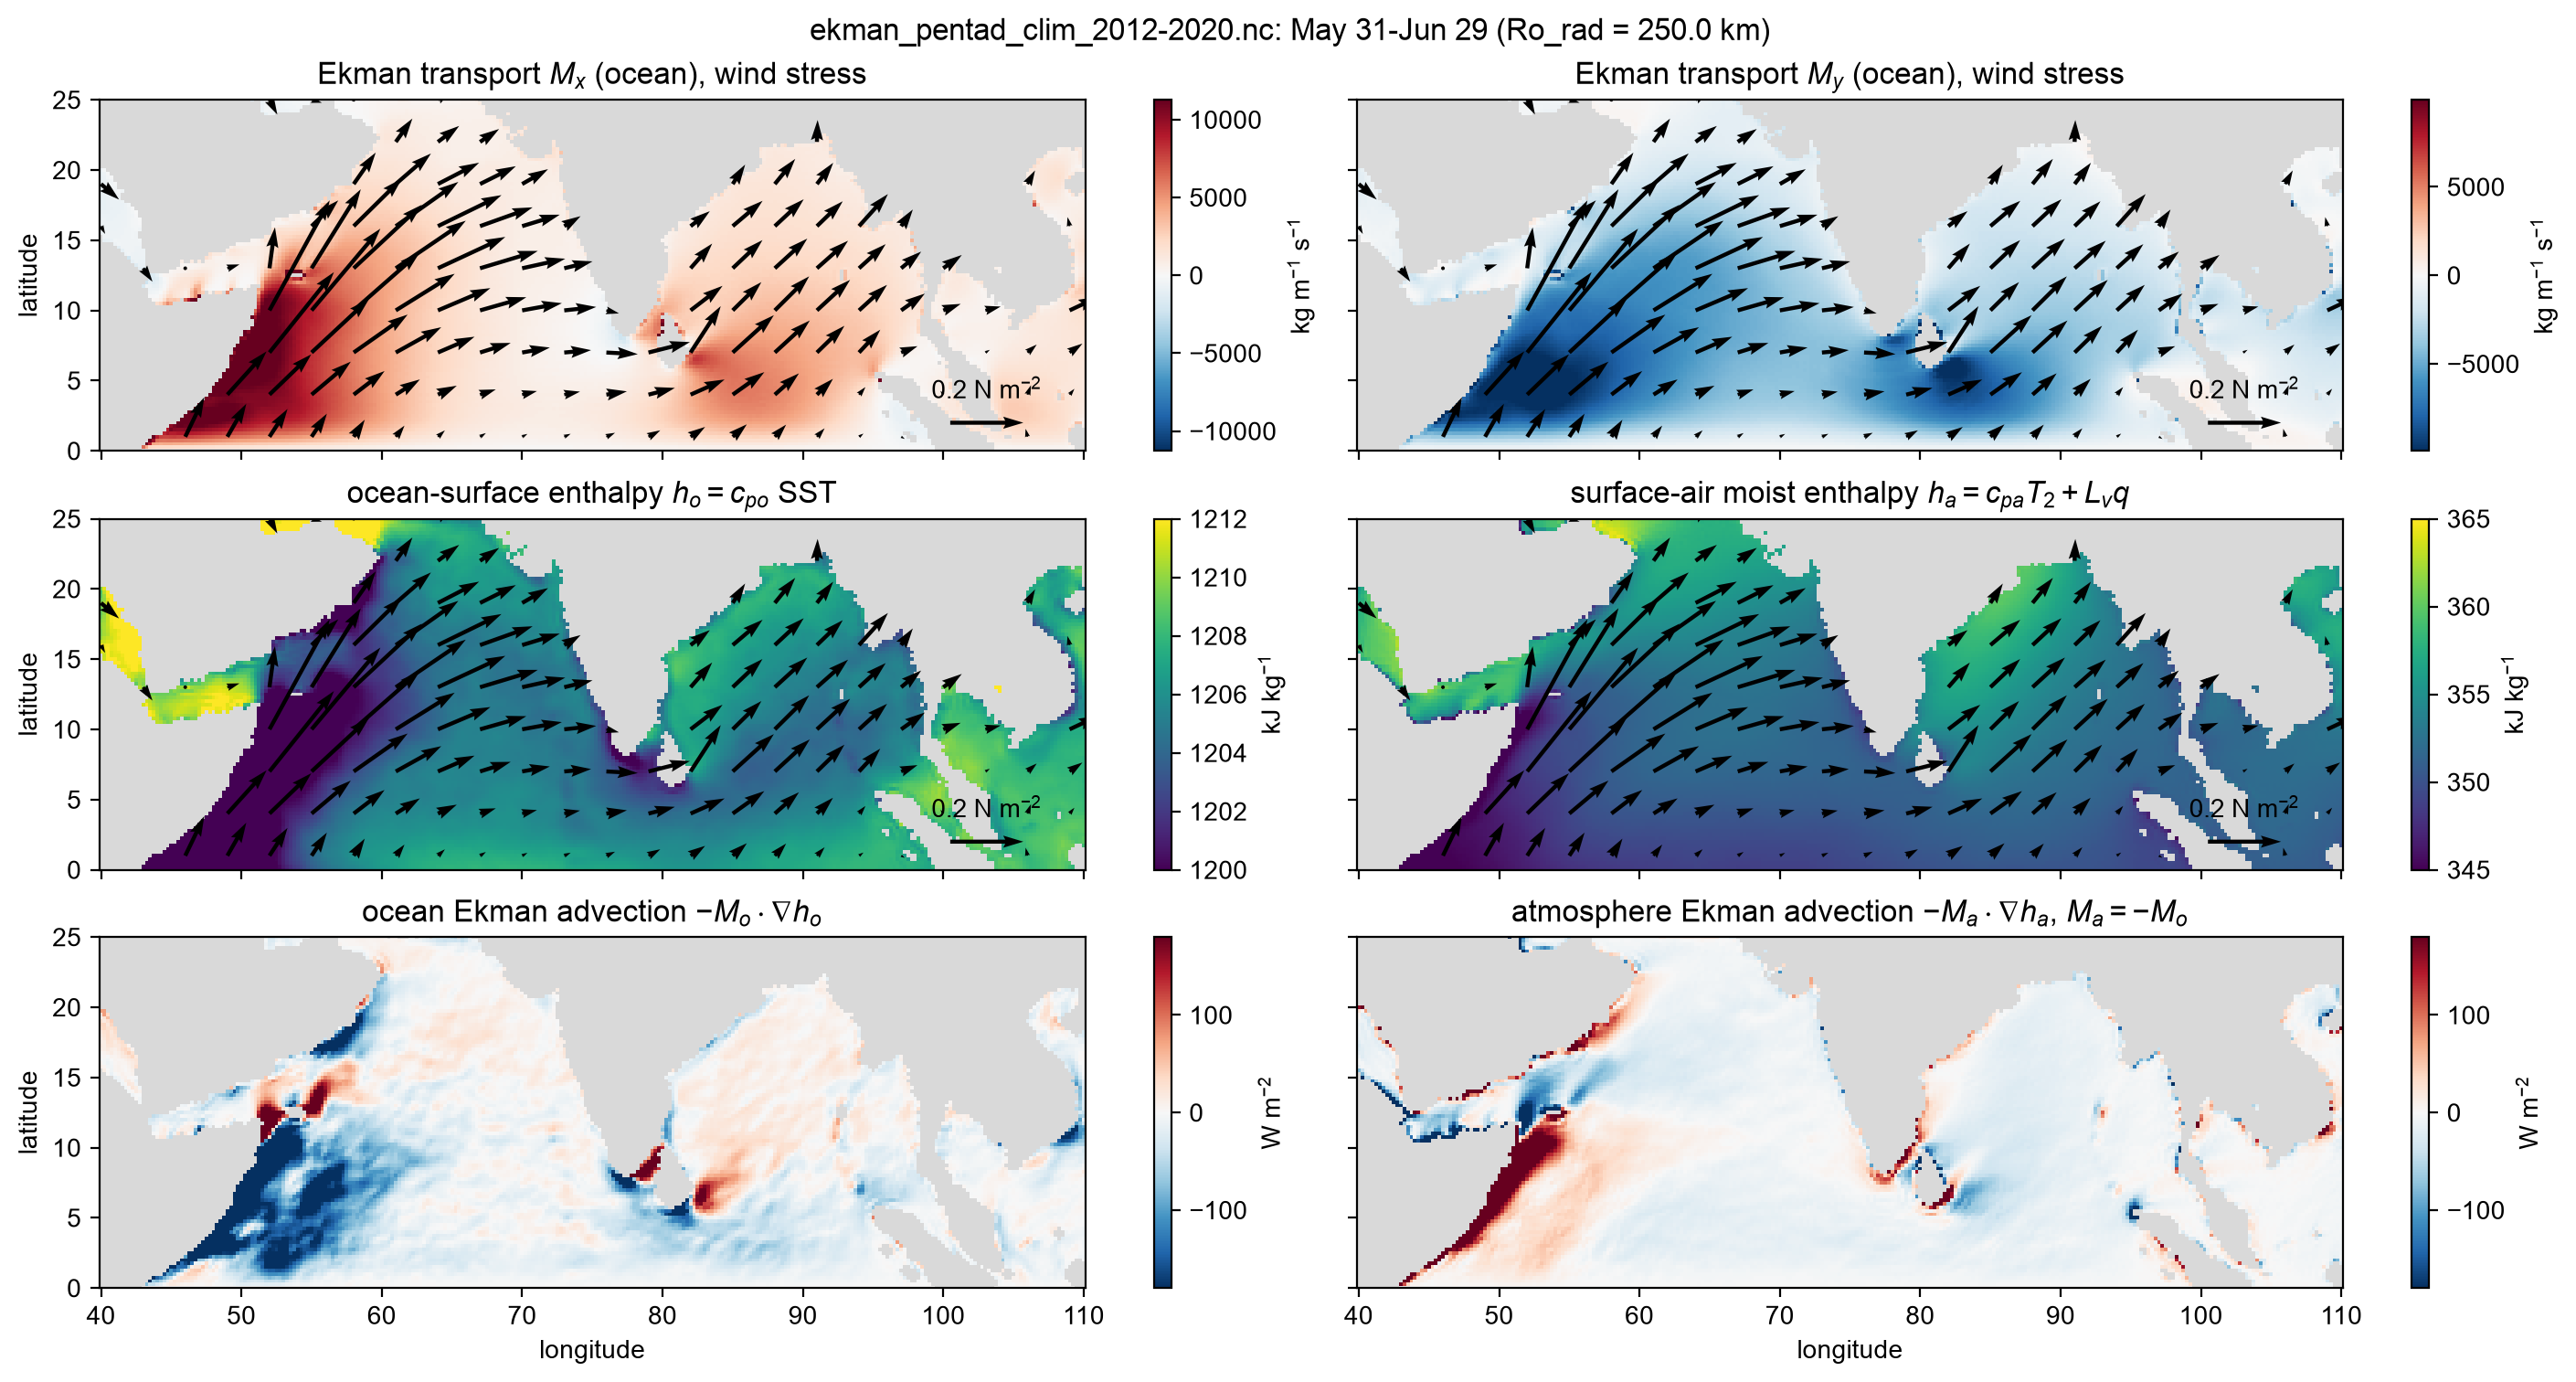

In [7]:
# any other period: read -> fields -> figure, e.g. June (pentads 31:36, May 31-Jun 29)
ho_lims, ha_lims, advlim = (1200, 1212), (345, 365), 180 # color limits: kJ/kg, kJ/kg, ±W/m^2
tau = stress_arrows(f_jun; scale=0.5, key=0.2) # June: 0.5 N m^-2 per inch, 0.2 N m^-2 key
fig_jun, axs_jun = plot_panels(f_jun, [
    panel(f_jun.Mx, raw"Ekman transport $M_x$ (ocean), wind stress", M_units; arrows=tau),
    panel(f_jun.My, raw"Ekman transport $M_y$ (ocean), wind stress", M_units; arrows=tau),
    panel(f_jun.h_o ./ 1e3, raw"ocean-surface enthalpy $h_o = c_{po}$ SST", h_units; arrows=tau, cmap="viridis", vmin=ho_lims[1], vmax=ho_lims[2]),
    panel(f_jun.h_a ./ 1e3, raw"surface-air moist enthalpy $h_a = c_{pa} T_2 + L_v q$", h_units; arrows=tau, cmap="viridis", vmin=ha_lims[1], vmax=ha_lims[2]),
    panel(f_jun.adv_o, raw"ocean Ekman advection $-M_o \cdot \nabla h_o$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f_jun.adv_a, raw"atmosphere Ekman advection $-M_a \cdot \nabla h_a$, $M_a = -M_o$", flux_units; vmin=-advlim, vmax=advlim)];
    suptitle=figtitle(f_jun), ylim=latlim);

## May to June: shift of ocean Ekman advection
Each panel colors ocean Ekman advection $-M_o \cdot \nabla h_o$ (±`advlim`), contours SST (°C, `sst_levels`) and quivers wind stress, for May (`f_may`), May 20-Jun 10 (`f_mayjun`) and June (`f_jun`, from the cell above). Each panel is a `panel` of `f_may.adv_o` with `contours` and `arrows`; `plot_panels` draws the list.

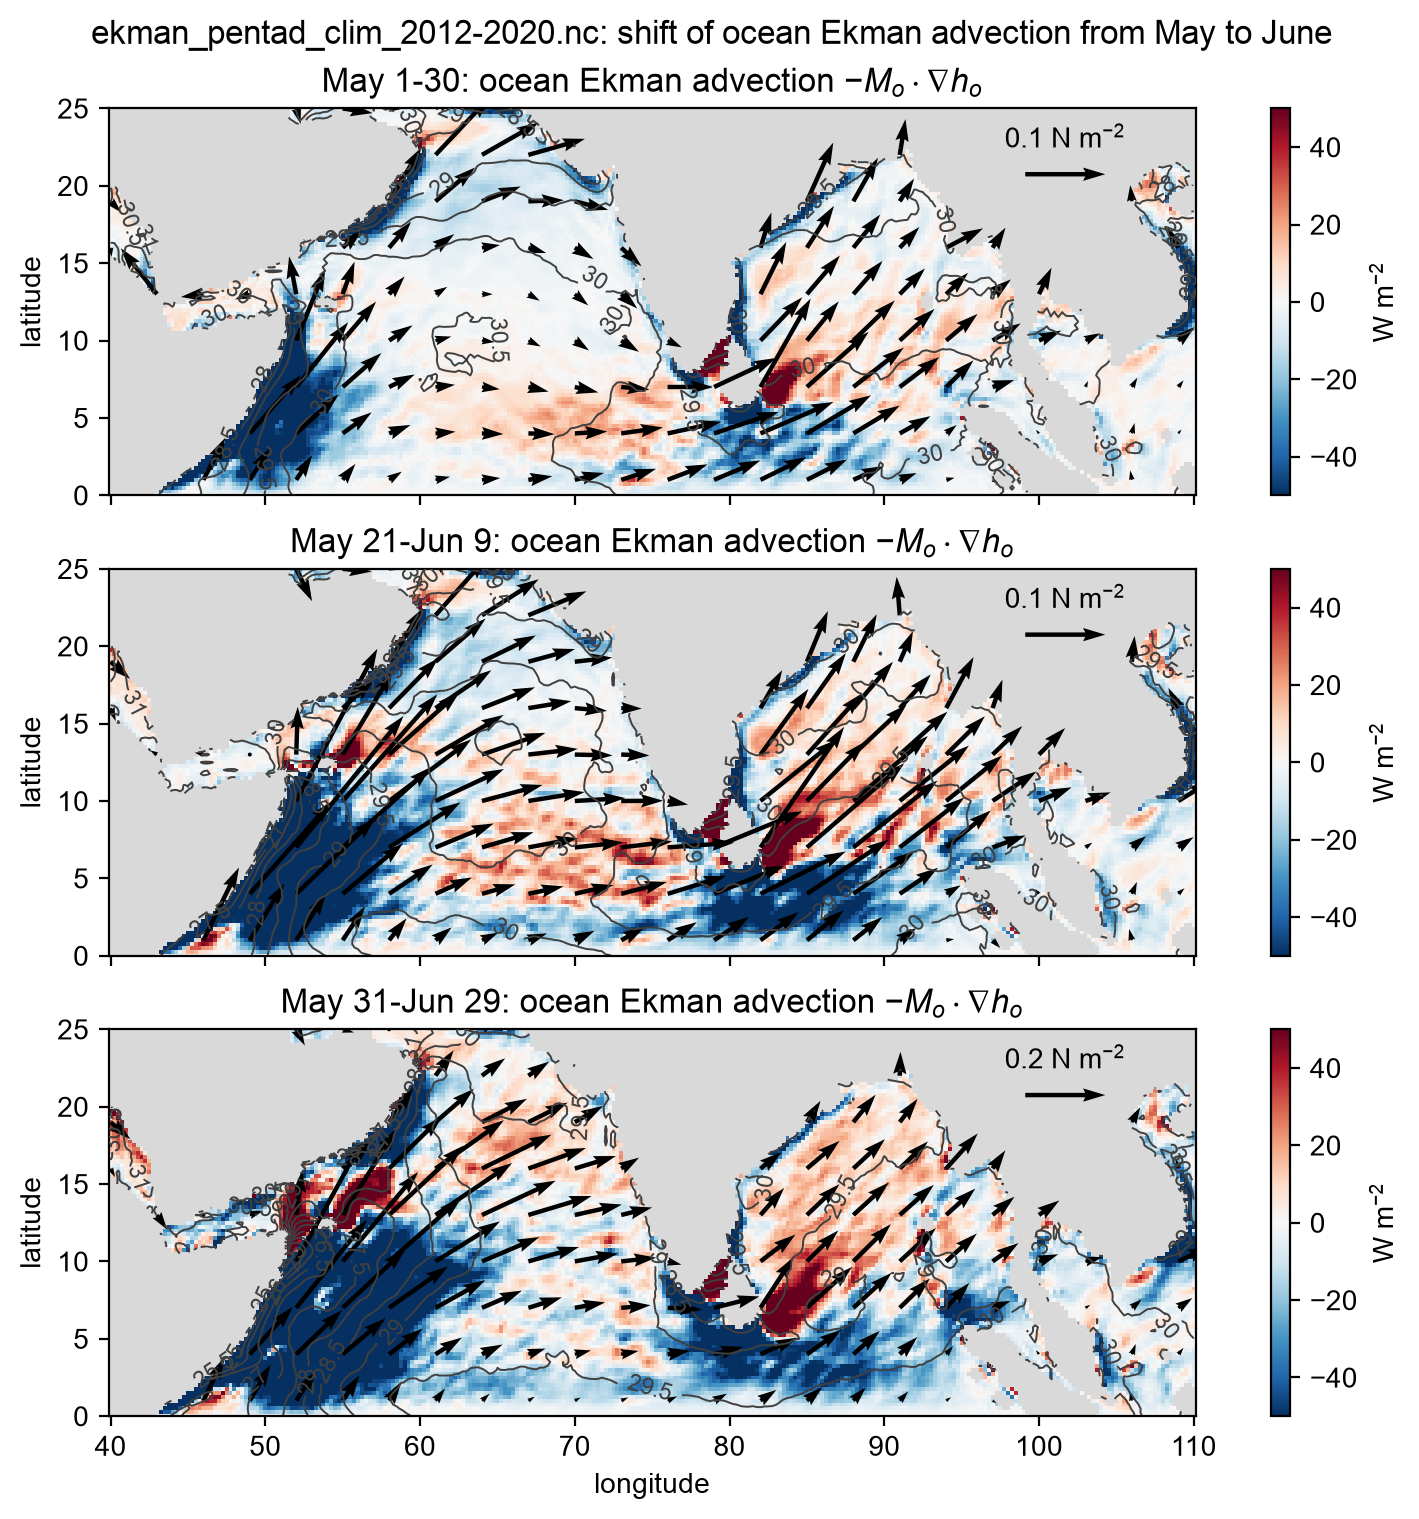

In [8]:
# May to June: each panel colors ocean Ekman advection, contours SST (°C), quivers wind stress
advlim = 50            # W m^-2: colors ±advlim
sst_levels = 24:0.5:31 # °C
ne = (0.88, 0.83)      # wind stress key position (axes fraction): northeast corner, over land
fig_shift, axs_shift, meshes_shift, cbars_shift, quivers_shift, contoursets_shift = plot_panels(f_may, [
    panel(f_may.adv_o, period_label(f_may.dimval) * raw": ocean Ekman advection $-M_o \cdot \nabla h_o$", flux_units; vmin=-advlim, vmax=advlim,
        contours=sst_contours(f_may; levels=sst_levels),
        arrows=stress_arrows(f_may; scale=0.25, key=0.1, keypos=ne)), # May arrows twice as long as June's
    panel(f_mayjun.adv_o, period_label(f_mayjun.dimval) * raw": ocean Ekman advection $-M_o \cdot \nabla h_o$", flux_units; vmin=-advlim, vmax=advlim,
        contours=sst_contours(f_mayjun; levels=sst_levels),
        arrows=stress_arrows(f_mayjun; scale=0.25, key=0.1, keypos=ne)),
    panel(f_jun.adv_o, period_label(f_jun.dimval) * raw": ocean Ekman advection $-M_o \cdot \nabla h_o$", flux_units; vmin=-advlim, vmax=advlim,
        contours=sst_contours(f_jun; levels=sst_levels),
        arrows=stress_arrows(f_jun; scale=0.5, key=0.2, keypos=ne))];
    ncols=1, ylim=latlim, suptitle="$(basename(file)): shift of ocean Ekman advection from May to June");
# fig_shift.savefig("ekman_adv_o_$(period_tag(f_may.dimval))_$(period_tag(f_jun.dimval)).png"; bbox_inches="tight")

June (monsoon season) wind drive frictional Ekman warm advection in the ocean in the northern Indian Ocean, both in the western Bay of Benga and the northern Arabian Sea (AS). The wind shifts from 5 N to 15 N in the central AS.

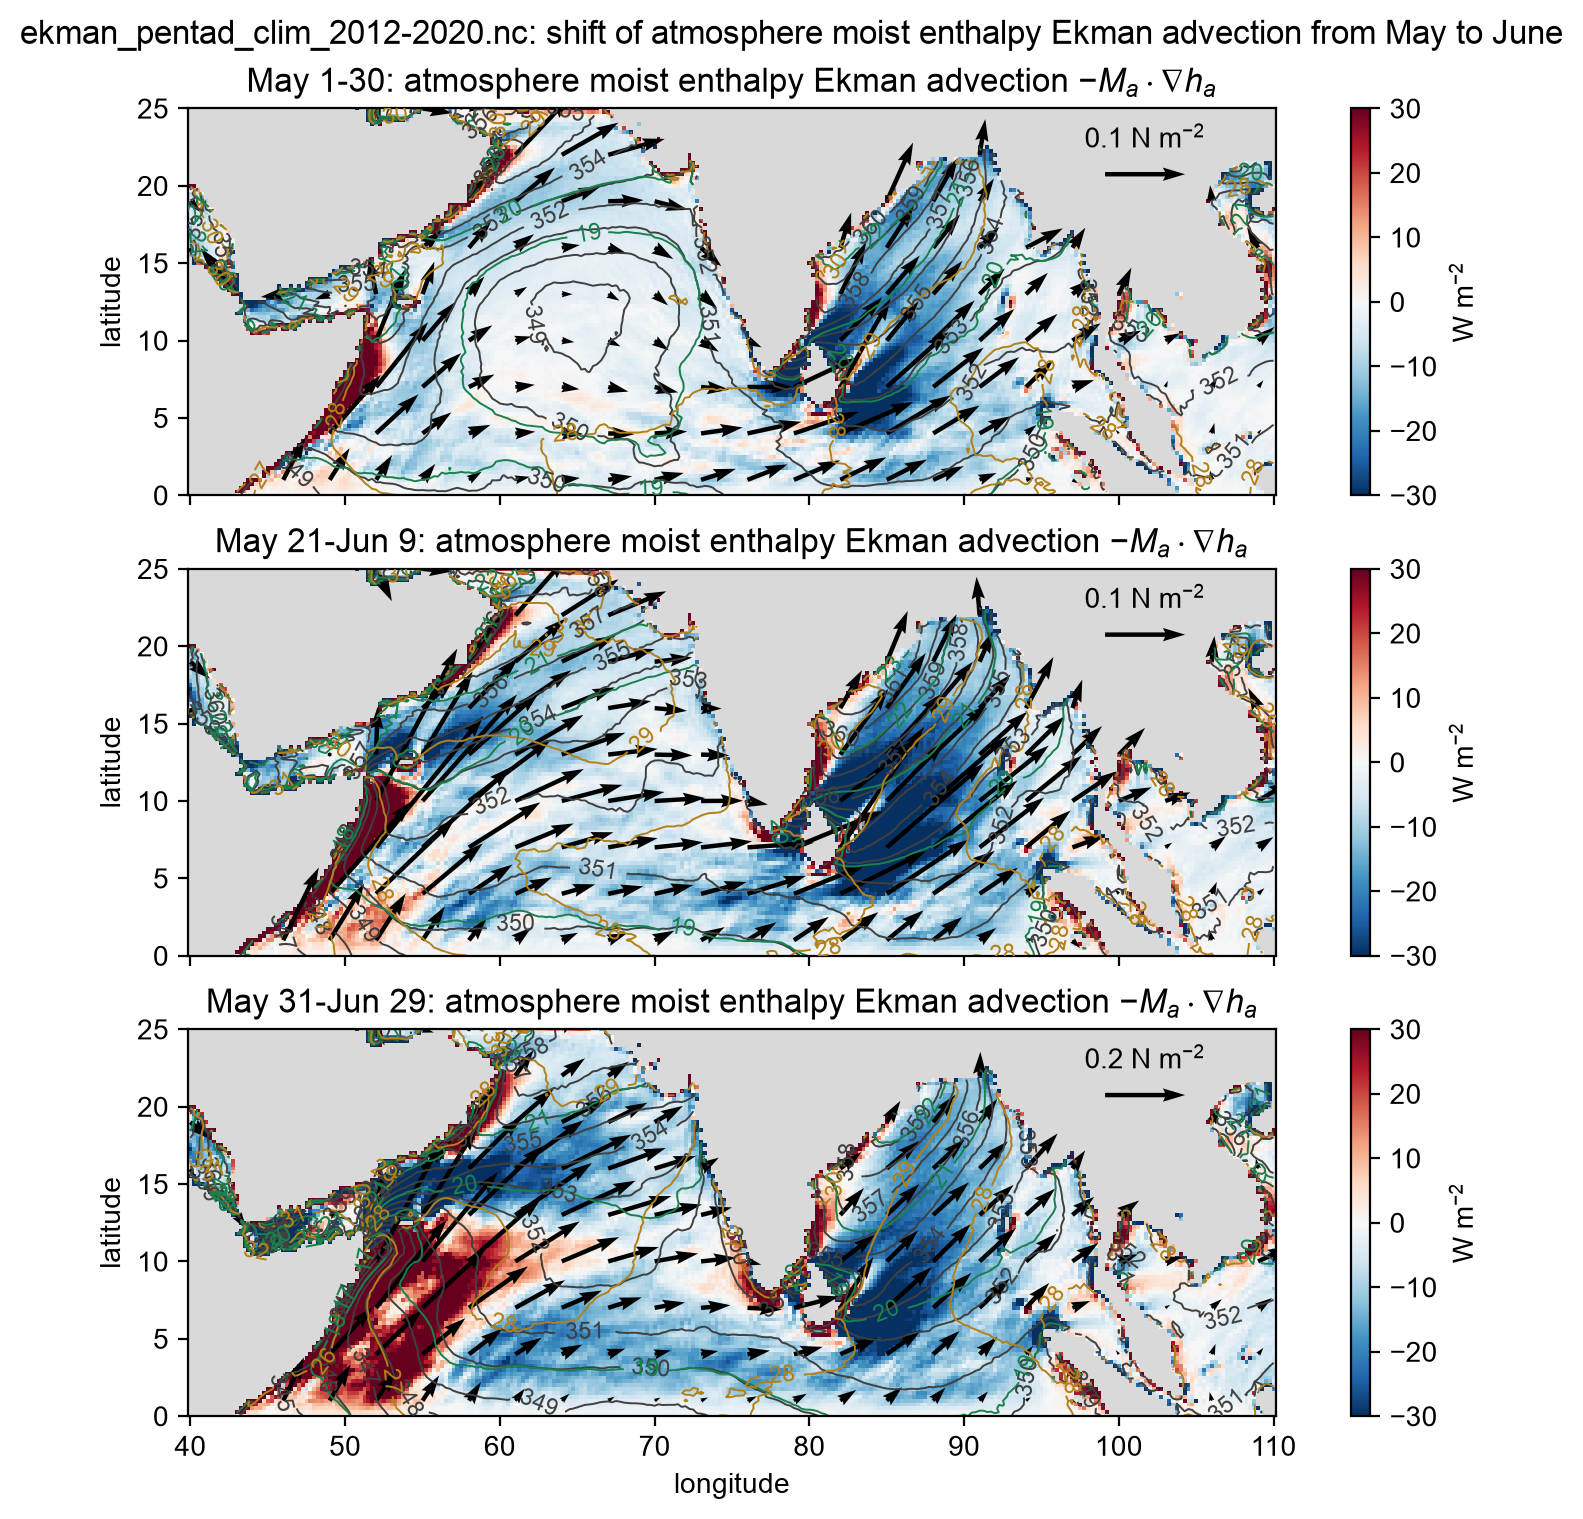

In [11]:
# plot atmosphere moist enthalpy advection for May to June
advlim = 30            # W m^-2: colors ±advlim
h_levels = round(minimum(f_may.h_a/1e3)):round(maximum(f_may.h_a/1e3)) # kJ/kg
q_levels = round(minimum(f_may.q*1e3)):round(maximum(f_may.q*1e3)) # g/kg
t2_levels = round(minimum(f_may.t2.-273.15)):round(maximum(f_may.t2.-273.15)) # °C
ne = (0.88, 0.83)      # wind stress key position (axes fraction): northeast corner, over land
fig_ashift, axs_ashift, meshes_ashift, cbars_ashift, quivers_ashift, contoursets_ashift = plot_panels(f_may, [
    panel(f_may.adv_a, period_label(f_may.dimval) * raw": atmosphere moist enthalpy Ekman advection $-M_a \cdot \nabla h_a$", flux_units; vmin=-advlim, vmax=advlim,
        contours=[contours(f_may.h_a/1e3; levels=h_levels, colors="0.25"),
                  contours(f_may.q*1e3; levels=q_levels, colors=[(0.1, 0.5, 0.3)]),
                  contours(f_may.t2.-273.15; levels=t2_levels, colors=[(0.7, 0.5, 0.1)])],
        arrows=stress_arrows(f_may; scale=0.25, key=0.1, keypos=ne)), # May arrows twice as long as June's
    panel(f_mayjun.adv_a, period_label(f_mayjun.dimval) * raw": atmosphere moist enthalpy Ekman advection $-M_a \cdot \nabla h_a$", flux_units; vmin=-advlim, vmax=advlim,
        contours=[contours(f_mayjun.h_a/1e3; levels=h_levels, colors="0.25"),
                  contours(f_mayjun.q*1e3; levels=q_levels, colors=[(0.1, 0.5, 0.3)]),
                  contours(f_mayjun.t2.-273.15; levels=t2_levels, colors=[(0.7, 0.5, 0.1)])],
        arrows=stress_arrows(f_mayjun; scale=0.25, key=0.1, keypos=ne)),
    panel(f_jun.adv_a, period_label(f_jun.dimval) * raw": atmosphere moist enthalpy Ekman advection $-M_a \cdot \nabla h_a$", flux_units; vmin=-advlim, vmax=advlim,
        contours=[contours(f_jun.h_a/1e3; levels=h_levels, colors="0.25"),
                  contours(f_jun.q*1e3; levels=q_levels, colors=[(0.1, 0.5, 0.3)]),
                  contours(f_jun.t2.-273.15; levels=t2_levels, colors=[(0.7, 0.5, 0.1)])],
        arrows=stress_arrows(f_jun; scale=0.5, key=0.2, keypos=ne))];
    ncols=1, ylim=latlim, suptitle="$(basename(file)): shift of atmosphere moist enthalpy Ekman advection from May to June");
